# 03 · Fine-tune the four transformers (Experiment 1)

**mBERT · XLM-R · MuRIL · HingBERT**, identical settings, **3 seeds each** → 12 runs.

| Setting | Value |
|---|---|
| learning rate | 2e-5, linear decay, 10 % warm-up |
| batch size | 32 |
| epochs | 4 (best epoch picked on **val** weighted F1) |
| max length | 128 tokens |
| seeds | 42, 43, 44 |

For every run we save the **logits** for val and test. Notebook 04 (Trustworthy) and 07 (final table) only need those, so they run on a laptop.

### How to run on Colab
1. Upload the `CS685_Hinglish` folder (from `hinglish_colab_bundle.zip`) to **Google Drive → My Drive**.
2. Open this notebook from Drive in Colab → **Runtime → Change runtime type → T4 GPU**.
3. Run all. If Colab disconnects, just **run all again**: finished runs are skipped automatically.

Rough time on a T4: ~5-8 min per run → about **1.5-2 h** for all 12. Results land in `My Drive/CS685_Hinglish/runs/`.

## 0. Setup

In [1]:
import os, sys, json
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/CS685_Hinglish")
    !pip -q install "transformers>=4.44" sentencepiece ftfy
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

assert (ROOT / "src/hinglish/train.py").exists(), f"Project not found at {ROOT} - upload the CS685_Hinglish folder to My Drive"
sys.path.insert(0, str(ROOT / "src"))
RUNS = ROOT / "runs"; RUNS.mkdir(exist_ok=True)

import torch, transformers, numpy as np, pandas as pd
print("transformers", transformers.__version__, "| torch", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (MPS)" if torch.backends.mps.is_available() else "none - CPU only, this will be very slow")

/Users/rahullalwani/Documents/IITMandi/Sem1/NLP/Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


transformers 5.22.1 | torch 2.15.0
GPU: none (MPS)


In [2]:
from hinglish.data import load_splits, LABELS
from hinglish.train import MODELS, TrainConfig, run_finetune, keep_best_checkpoint_only

S = load_splits(ROOT / "data/processed")
print({k: len(v) for k, v in S.items()})
MODELS

{'train': 14000, 'val': 3000, 'test': 3000}


{'mbert': 'google-bert/bert-base-multilingual-cased',
 'xlmr': 'FacebookAI/xlm-roberta-base',
 'muril': 'google/muril-base-cased',
 'hingbert': 'l3cube-pune/hing-bert'}

## 1. Smoke test (≈1 min)

Trains mBERT on 256 tweets for 1 epoch, just to prove the whole pipeline works before spending GPU hours. Output goes to `runs_smoke/`, not `runs/`.

In [3]:
smoke = run_finetune("mbert", 0, S, ROOT / "runs_smoke",
                     TrainConfig(epochs=1, limit_train=256, limit_eval=256), save_model=False)
print({k: smoke[k] for k in ["model_key", "device", "train_minutes", "test"]})

[skip] mbert seed0 already done
{'model_key': 'mbert', 'device': 'mps', 'train_minutes': 0.1, 'test': {'weighted_f1': 0.14230913173652696, 'macro_f1': 0.15568862275449102, 'accuracy': 0.3046875, 'ece': 0.1283913382794708}}


## 2. Full runs: 4 models × 3 seeds

* `SAVE_MODEL=True` keeps checkpoints. After all seeds of a model finish, only the **best-val seed's** checkpoint is kept (~1 GB each), which notebooks 05/06 use as the teacher.
* Re-running this cell is safe; completed runs are skipped.

In [4]:
CFG = TrainConfig()           # identical settings for every model
SEEDS = [42, 43, 44]
ORDER = ["mbert", "xlmr", "muril", "hingbert"]
SAVE_MODEL = True

for key in ORDER:
    for seed in SEEDS:
        print(f"\n=== {key} ({MODELS[key]}) seed {seed} ===")
        run_finetune(key, seed, S, RUNS, CFG, save_model=SAVE_MODEL)
    if SAVE_MODEL:
        print(f"kept checkpoint: {key} seed{keep_best_checkpoint_only(RUNS, key)}")


=== mbert (google-bert/bert-base-multilingual-cased) seed 42 ===
[skip] mbert seed42 already done

=== mbert (google-bert/bert-base-multilingual-cased) seed 43 ===
[skip] mbert seed43 already done

=== mbert (google-bert/bert-base-multilingual-cased) seed 44 ===
[skip] mbert seed44 already done
kept checkpoint: mbert seed43

=== xlmr (FacebookAI/xlm-roberta-base) seed 42 ===
[skip] xlmr seed42 already done

=== xlmr (FacebookAI/xlm-roberta-base) seed 43 ===
[skip] xlmr seed43 already done

=== xlmr (FacebookAI/xlm-roberta-base) seed 44 ===
[skip] xlmr seed44 already done
kept checkpoint: xlmr seed43

=== muril (google/muril-base-cased) seed 42 ===
[skip] muril seed42 already done

=== muril (google/muril-base-cased) seed 43 ===
[skip] muril seed43 already done

=== muril (google/muril-base-cased) seed 44 ===
[skip] muril seed44 already done
kept checkpoint: muril seed44

=== hingbert (l3cube-pune/hing-bert) seed 42 ===
[skip] hingbert seed42 already done

=== hingbert (l3cube-pune/hin

## 3. Results

In [5]:
rows = []
for p in sorted(RUNS.glob("*/seed*/result.json")):
    r = json.loads(p.read_text())
    rows.append({"model": r["model_key"], "seed": r["seed"], "params (M)": r["n_params_M"],
                 "best epoch": r["best_epoch"], "minutes": r["train_minutes"],
                 "val wF1": r["val"]["weighted_f1"], "test wF1": r["test"]["weighted_f1"],
                 "test macro F1": r["test"]["macro_f1"], "test acc": r["test"]["accuracy"],
                 "test ECE": r["test"]["ece"], "T": r["temperature"], "test ECE after T": r["test_ece_after_T"]})
runs = pd.DataFrame(rows)
runs.round(4)

,model,seed,params (M),best epoch,minutes,val wF1,test wF1,test macro F1,test acc,test ECE,T,test ECE after T
0,hingbert,42,109.5,4,7.7,0.6593,0.7120,0.7156,0.7110,0.1161,1.9052,0.0567
1,hingbert,43,109.5,3,7.8,0.6631,0.7157,0.7194,0.7160,0.0784,1.6121,0.0475
2,hingbert,44,109.5,4,12.2,0.6535,0.7104,0.7142,0.7093,0.1197,1.8794,0.0429
3,mbert,42,177.9,2,8.8,0.6033,0.6627,0.6680,0.6693,0.0253,1.2496,0.0527
4,mbert,43,177.9,3,8.7,0.6167,0.6877,0.6899,0.6853,0.0332,1.4395,0.0565
5,mbert,44,177.9,3,8.7,0.6055,0.6905,0.6943,0.6930,0.0579,1.5544,0.0584
6,muril,42,237.6,4,10.0,0.6337,0.7059,0.7088,0.7050,0.0304,1.2130,0.0652
7,muril,43,237.6,4,9.7,0.6300,0.7022,0.7061,0.7030,0.0445,1.2388,0.0717
8,muril,44,237.6,4,9.9,0.6403,0.7046,0.7080,0.7047,0.0326,1.2440,0.0610
9,xlmr,42,278.0,4,9.8,0.6276,0.7162,0.7198,0.7173,0.0503,1.5725,0.0721


In [6]:
metrics = ["test wF1", "test macro F1", "test ECE", "T", "test ECE after T"]
agg = runs.groupby("model")[metrics].agg(["mean", "std"])
summary = pd.DataFrame({m: agg[(m, "mean")].map("{:.4f}".format) + " ± " + agg[(m, "std")].fillna(0).map("{:.4f}".format) for m in metrics})
summary["params (M)"] = runs.groupby("model")["params (M)"].first()

base = json.loads((ROOT / "results/02_baseline_tfidf.json").read_text())
summary.loc["tfidf_lr (02)"] = [f"{base['test_weighted_f1']:.4f}", f"{base['test_macro_f1']:.4f}",
                                f"{base['test_ece_before']:.4f}", f"{base['temperature']:.2f}", f"{base['test_ece_after']:.4f}", "-"]
order = [m for m in ORDER if m in summary.index] + ["tfidf_lr (02)"]
summary = summary.loc[order]
display(summary)
print("References (SemEval-2020): mBERT baseline 65.4 · winner 75.0 (weighted F1 x100)")

(ROOT / "results").mkdir(exist_ok=True)
runs.to_csv(ROOT / "results/03_transformer_runs.csv", index=False)
summary.to_csv(ROOT / "results/03_transformer_summary.csv")

/var/folders/jn/61wqcfhd1z1b9lrnw5166dmh0000gn/T/ipykernel_84793/3257496057.py:7: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype float64 cannot hold the value being set, so the result has dtype object. Cast the object to object before this operation to retain the current behavior.
  summary.loc["tfidf_lr (02)"] = [f"{base['test_weighted_f1']:.4f}", f"{base['test_macro_f1']:.4f}",


,test wF1,test macro F1,test ECE,T,test ECE after T,params (M)
model,,,,,,
mbert,0.6803 ± 0.0153,0.6841 ± 0.0141,0.0388 ± 0.0170,1.4145 ± 0.1540,0.0559 ± 0.0029,177.9
xlmr,0.7075 ± 0.0083,0.7110 ± 0.0082,0.0516 ± 0.0117,1.5530 ± 0.0546,0.0650 ± 0.0063,278.0
muril,0.7042 ± 0.0019,0.7076 ± 0.0014,0.0358 ± 0.0076,1.2319 ± 0.0166,0.0659 ± 0.0054,237.6
hingbert,0.7127 ± 0.0027,0.7164 ± 0.0027,0.1047 ± 0.0229,1.7989 ± 0.1623,0.0490 ± 0.0070,109.5
tfidf_lr (02),0.6872,0.6903,0.0732,0.93,0.0605,-


References (SemEval-2020): mBERT baseline 65.4 · winner 75.0 (weighted F1 x100)


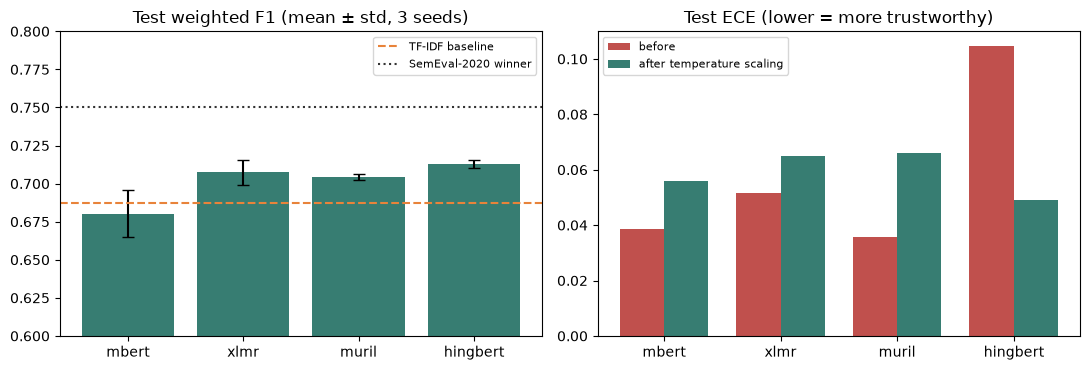

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
m = runs.groupby("model").agg(f1=("test wF1", "mean"), f1s=("test wF1", "std"),
                              e=("test ECE", "mean"), ea=("test ECE after T", "mean")).reindex([o for o in ORDER if o in runs.model.unique()])
axes[0].bar(m.index, m.f1, yerr=m.f1s, color="#377D72", capsize=4)
axes[0].axhline(base["test_weighted_f1"], ls="--", color="#E8833A", label="TF-IDF baseline")
axes[0].axhline(0.750, ls=":", color="#333", label="SemEval-2020 winner")
axes[0].set_ylim(0.6, 0.8); axes[0].set_title("Test weighted F1 (mean ± std, 3 seeds)"); axes[0].legend(fontsize=8)
x = np.arange(len(m)); w = 0.38
axes[1].bar(x - w/2, m.e, w, color="#C0504D", label="before")
axes[1].bar(x + w/2, m.ea, w, color="#377D72", label="after temperature scaling")
axes[1].set_xticks(x, m.index); axes[1].set_title("Test ECE (lower = more trustworthy)"); axes[1].legend(fontsize=8)
plt.tight_layout(); (ROOT / "results/figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "results/figures/03_transformers_f1_ece.png"); plt.show()

## 4. Try the best model on the slide examples

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from hinglish.data import normalise
from scipy.special import softmax

best = runs.loc[runs["val wF1"].idxmax()]          # chosen on VAL, not test
best_dir = RUNS / best.model / f"seed{best.seed}" / "model"
print("best (by val):", best.model, "seed", best.seed, "| T =", round(best["T"], 2))
tok = AutoTokenizer.from_pretrained(best_dir)
clf = AutoModelForSequenceClassification.from_pretrained(best_dir).eval()

def predict(text, T=best["T"]):
    with torch.no_grad():
        z = clf(**tok(normalise(text), return_tensors="pt")).logits.numpy()
    p = softmax(z / T, axis=1)[0]
    return {"label": LABELS[p.argmax()], "scores": {l[:3]: round(float(s), 2) for l, s in zip(LABELS, p)}}

for t in ["Movie ekdum bakwas thi, total waste of time",
          "All the best Team India jeet ke aana",
          "Nahi wo is news ko defend kerne ki koshesh ker rhe hain h"]:
    print(f"{t!r:65} -> {predict(t)}")

best (by val): hingbert seed 43 | T = 1.61


W1116 02:07:55.375000 84793 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 9996.03it/s]

'Movie ekdum bakwas thi, total waste of time'                     -> {'label': 'negative', 'scores': {'neg': 0.62, 'neu': 0.27, 'pos': 0.11}}
'All the best Team India jeet ke aana'                            -> {'label': 'positive', 'scores': {'neg': 0.09, 'neu': 0.21, 'pos': 0.7}}
'Nahi wo is news ko defend kerne ki koshesh ker rhe hain h'       -> {'label': 'neutral', 'scores': {'neg': 0.36, 'neu': 0.51, 'pos': 0.14}}


## Next
* Download `runs/*/seed*/logits.npz` + `result.json` (small) → notebook **04_trustworthy** runs locally.
* Best checkpoint = **teacher** for **06_efficiency** (vocab trim → distil → int8).